# NMF-OT

Configurations of this notebook:
- WNMF: use the version translated from MATLAB. 
- KLNMF: use the version implemented in SCIKIT LEARN. 
- Ground cost matrix: fixed linear combination of Hamming distance at each positions


## Simulate the data

In [1]:
import pandas as pd 
import numpy as np 
import random
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
import time
from wassersteinDL import wasserstein_DL
import warnings
import os
from config import *

# use scikit-learn for the baseline KLNMF
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning

from scipy.optimize import linear_sum_assignment, nnls

outputdir = "./tmp_output/sig_plots"
os.system(f"mkdir -p {outputdir}")

cosmic = pd.read_csv(COSMIC_FILE, sep="\t", index_col=0)
sbs96 = cosmic.index
all_cosmic_sigs = cosmic.columns

# cosmic.head()
# select some SBS from the COSMIC catalog to simulate the data. 

# number of signatures from COSMIC
k = 10

# number of samples in the dataset
N = 200

cosmic_sigs = random.sample(list(all_cosmic_sigs), k)

print(f"Selected COSMIC signature to do simulation: {cosmic_sigs}")

W_true = cosmic[cosmic_sigs].to_numpy()
rng = np.random.default_rng(SEED)
H_prop = np.zeros((k, N))
for j in range(N):
    active = rng.random(k) < 0.5
    active[0] = True # first SBS on the list is always on
    H_prop[active, j] = rng.dirichlet(np.ones(active.sum()))
burden = rng.lognormal(np.log(1000), 0.7, N)

# multiply the proportion, tumor burden and the signatures to get simulated real counts
mu = W_true @ (H_prop * burden)

# NB_DISPERSION
r = 50                                   

# the final SBS 96 x N matrix for running NMF - KLNMF - WNMF
X = rng.negative_binomial(r, r / (r + mu))


Selected COSMIC signature to do simulation: ['SBS25', 'SBS96', 'SBS23', 'SBS40b', 'SBS85', 'SBS46', 'SBS54', 'SBS41', 'SBS38', 'SBS7a']


## Define the ground cost matrix

Here we use a simple ground cost matrix. We weight the substitution in two flanking positions 1, and main sub 2. 

`M = 1 * differs(prime5) + 2 * differs(sub) + 1 * differs(prime3)`

Please change this section if you have a different fixed ground cost matrix. This cannot apply the "learned" ground cost matrix. We will do it in another notebook. 

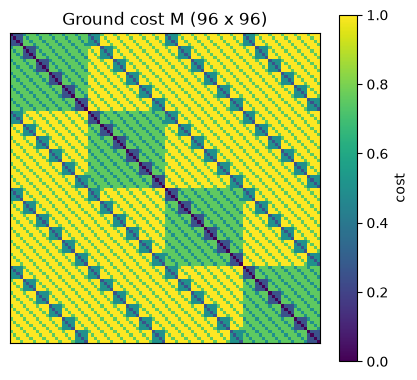

In [2]:
prime5  = sbs96.str[0].to_numpy()
sub   = sbs96.str[2:5].to_numpy()
prime3 = sbs96.str[-1].to_numpy()
differs = lambda x: (x[:, None] != x[None, :]).astype(float)

M = 1 * differs(prime5) + 2 * differs(sub) + 1 * differs(prime3)
M = M / M.max()
# M = pd.read_csv(REPO / "data/cost_matrix/C_graph_struct_scaled.csv", index_col=0).loc[sbs96, sbs96].to_numpy()

plt.figure(figsize=(5, 4.5))
plt.imshow(M, cmap="viridis"); plt.colorbar(label="cost")
plt.title("Ground cost M (96 x 96)"); plt.xticks([]); plt.yticks([])
plt.show()

In [3]:
# ***** save M for later use
pd.DataFrame(M, index=sbs96, columns=sbs96).to_csv(os.path.join(outputdir, "M.csv"), float_format="%.10g")

## One-time test-run for the WNMF

done in 13s, 12 outer iterations
S_wnmf: (96, 10)  column sums [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
lambda: (10, 200)  column sums (first 5) [1. 1. 1. 1. 1.]


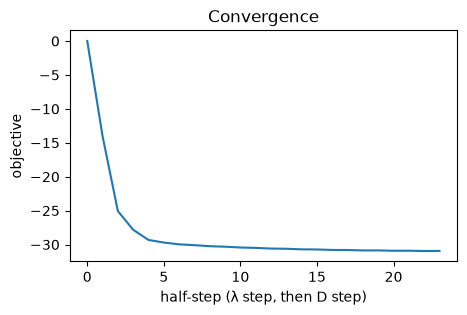

In [4]:
P = X / X.sum(0, keepdims=True) # make sure everything is histogram.

gamma = 1 / 50
rhoL = rhoD = 0.05
options = {"stop": 1e-3, 
           "D_step_stop": 5e-5, 
           "lambda_step_stop": 5e-4,
           "alpha": 0.5, 
           "Kmultiplication": 
           "symmetric", 
           "verbose": 0}

t = time.time()
S_wnmf, lam, objectives, E_wnmf, Hlambda = wasserstein_DL(P, k, M, gamma, rhoL, rhoD, options,
                                                 rng=np.random.default_rng(1))
print(f"done in {time.time() - t:.0f}s, {len(objectives) // 2} outer iterations")
print("S_wnmf:", S_wnmf.shape, " column sums", S_wnmf.sum(0).round(3))
print("lambda:", lam.shape, " column sums (first 5)", lam.sum(0)[:5].round(3))

plt.figure(figsize=(5, 3))
plt.plot(objectives); plt.xlabel("half-step (λ step, then D step)"); plt.ylabel("objective")
plt.title("Convergence"); plt.show()

## One-time test run for the KLNMF

In [5]:
# ***** helper functions
EPS = 1e-12
MAX_ITER, TOL = 5000, 1e-6 
N_RESTARTS, SEED = 10, 2025

def kl_div(X, WH):
    # generalised KL divergence D(X || WH), with 0 log 0 = 0 (same function as 05)
    X = np.asarray(X, float)
    return float(np.sum(np.where(X > 0, X * np.log((X + EPS) / (WH + EPS)), 0.0) - X + WH))

def sk_klnmf(X, K, init="random", seed=None, max_iter=MAX_ITER, tol=TOL):
    # one sklearn KL-NMF fit; W columns rescaled to the simplex, H in counts
    X = np.asarray(X, float)
    model = NMF(n_components=K, beta_loss="kullback-leibler", solver="mu", init=init,
                max_iter=max_iter, tol=tol, random_state=seed)
    t0 = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        W = model.fit_transform(X)
    H = model.components_.copy()
    s = W.sum(0, keepdims=True) + EPS
    W, H = W / s, H * s.T
    return dict(W=W, H=H, kl=kl_div(X, W @ H), n_iter=model.n_iter_, init=init, seed=seed,
                converged=not any(issubclass(w.category, ConvergenceWarning) for w in caught),
                seconds=time.time() - t0)


def fit_KLNMF(X, K, n_restarts=N_RESTARTS, seed=SEED, **kw):
    runs = [sk_klnmf(X, K, init="nndsvda", **kw)]
    runs += [sk_klnmf(X, K, init="random", seed=seed + r, **kw) for r in range(n_restarts)]
    best = min(runs, key=lambda d: d["kl"])
    return best, runs

# ***** main run KLNMF scikit-learn.
best, runs = fit_KLNMF(X, k)           # X: 96 x N counts (not proportions), K: number of signatures
S_klnmf, E_klnmf = best["W"], best["H"]      # W: 96 x K, columns sum to 1;  H: K x N, mutations per signature
print(best["kl"], best["n_iter"], best["converged"])

10614.981572368262 820 True


## Validation

We follow the validation section 3.3 in the report. 

In [6]:
# This cell contains the VALIDATION module

def cosine_similarity(A, B):
    """Calculate the cosine similartiy between the columns of A (n x p) and B (n x q) -> p x q."""
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B


def pam(Dist, k, max_iter=100):
    """PAM / k-medoids on a distance matrix: greedy BUILD start, then SWAP."""
    n = len(Dist)
    medoids = [int(np.argmin(Dist.sum(1)))]
    while len(medoids) < k:
        nearest = Dist[:, medoids].min(1)
        gain = np.maximum(nearest[:, None] - Dist, 0).sum(0)
        gain[medoids] = -np.inf
        medoids.append(int(np.argmax(gain)))
    medoids = np.array(medoids)
    cost = Dist[:, medoids].min(1).sum()
    for _ in range(max_iter):
        best = (cost, None, None)
        for mi in range(k):
            for h in range(n):
                if h in medoids:
                    continue
                trial = medoids.copy(); trial[mi] = h
                c = Dist[:, trial].min(1).sum()
                if c < best[0] - 1e-12:
                    best = (c, mi, h)
        if best[1] is None:
            break
        cost, medoids[best[1]] = best[0], best[2]
    return medoids, np.argmin(Dist[:, medoids], axis=1)


def consensus_signatures(runs, k):
    """Step 1-2: pool the signatures of all runs, cluster with PAM on cosine distance."""
    pooled = np.hstack(runs)                                  # 96 x (R*k)
    Dist = np.clip(1 - cosine_similarity(pooled, pooled), 0, None)
    np.fill_diagonal(Dist, 0)
    med, labels = pam(Dist, k)
    medoids = pooled[:, med] / pooled[:, med].sum(0)
    cohesion = np.array([1 - Dist[labels == c, med[c]].mean() for c in range(k)])
    return medoids, cohesion


def match_signatures(W_true, W_est):
    """Step 3: one-to-one Hungarian matching on cosine."""
    cs = cosine_similarity(W_true, W_est)
    r, c = linear_sum_assignment(-cs)
    return c, cs[r, c]                                        # est index per true sig, cosine


def confusion_at_cutoff(match_cos, n_est, t):
    """Step 4: TP / FP / FN at cosine cutoff t."""
    tp = int((match_cos >= t).sum())
    fp, fn = n_est - tp, len(match_cos) - tp
    prec, rec = tp / n_est, tp / len(match_cos)
    f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
    return dict(cutoff=t, TP=tp, FP=fp, FN=fn, precision=prec, TPR=rec, F1=f1)


def validate(W_true, runs, cutoffs=np.round(np.arange(0.70, 1.0001, 0.01), 2)):
    """Full section 3.3 validation: medoids, matches and the TPR curve (step 5)."""
    k = W_true.shape[1]
    medoids, cohesion = consensus_signatures(runs, k)
    idx, cos = match_signatures(W_true, medoids)
    curve = [confusion_at_cutoff(cos, medoids.shape[1], t) for t in cutoffs]
    return medoids, idx, cos, cohesion[idx], curve

W-NMF run 1/2 done (14s)
W-NMF run 2/2 done (31s)
W-NMF cosine per true signature: {'SBS25': np.float64(0.831), 'SBS96': np.float64(0.827), 'SBS23': np.float64(0.986), 'SBS40b': np.float64(0.831), 'SBS85': np.float64(0.886), 'SBS46': np.float64(0.883), 'SBS54': np.float64(0.991), 'SBS41': np.float64(0.944), 'SBS38': np.float64(0.998), 'SBS7a': np.float64(0.979)}
W-NMF cluster cohesion:          [0.831 1.    0.999 0.893 0.979 0.984 0.998 0.993 1.    0.999]
KL-NMF cosine per true signature: {'SBS25': np.float64(0.951), 'SBS96': np.float64(0.991), 'SBS23': np.float64(0.997), 'SBS40b': np.float64(0.959), 'SBS85': np.float64(0.994), 'SBS46': np.float64(0.983), 'SBS54': np.float64(0.999), 'SBS41': np.float64(0.998), 'SBS38': np.float64(0.999), 'SBS7a': np.float64(0.999)}
KL-NMF cluster cohesion:          [1.    0.999 1.    1.    1.    0.999 1.    1.    1.    1.   ]


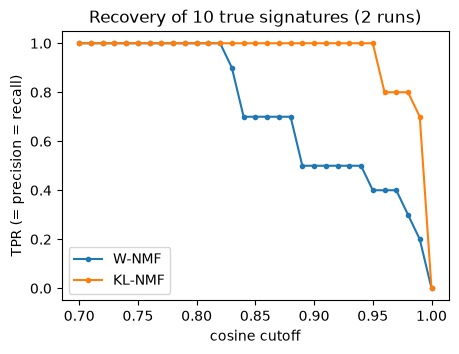

,W-NMF,KL-NMF
SBS25,0.831118,0.950889
SBS96,0.826734,0.990937
SBS23,0.986368,0.997444
SBS40b,0.831216,0.959316
SBS85,0.885635,0.994087
SBS46,0.883223,0.983447
SBS54,0.991082,0.998830
SBS41,0.943670,0.998408
SBS38,0.998413,0.999402
SBS7a,0.979353,0.998945


In [7]:
# ***** Run the validation module (section 3.3) on W-NMF and KL-NMF
# validate() expects a list of 96 x k signature matrices, one per independent run.
N_RUNS = 2

# W-NMF: one fit per seed, keep the dictionary D (= S, 96 x k). ~15 s per run.
runs_wnmf = []
t = time.time()
for r in range(N_RUNS):
    S_r = wasserstein_DL(P, k, M, gamma, rhoL, rhoD, options,
                         rng=np.random.default_rng(100 + r))[0]
    runs_wnmf.append(S_r)
    print(f"W-NMF run {r + 1}/{N_RUNS} done ({time.time() - t:.0f}s)")

# KL-NMF: one random-init sklearn fit per seed (not fit_KLNMF, which would do 11 fits per run
# and return a dict). sk_klnmf already rescales W columns to the simplex.
runs_klnmf = [sk_klnmf(X, k, init="random", seed=100 + r)["W"] for r in range(N_RUNS)]

results = {}
plt.figure(figsize=(5, 3.5))
for name, sig_runs in [("W-NMF", runs_wnmf), ("KL-NMF", runs_klnmf)]:
    medoids, idx, cos, coh, curve = validate(W_true, sig_runs)
    curve = pd.DataFrame(curve).set_index("cutoff")
    results[name] = dict(medoids=medoids, idx=idx, cos=cos, cohesion=coh, curve=curve)
    print(f"{name} cosine per true signature:", dict(zip(cosmic_sigs, cos.round(3))))
    print(f"{name} cluster cohesion:         ", coh.round(3))
    plt.plot(curve.index, curve.TPR, marker="o", ms=3, label=name)
plt.xlabel("cosine cutoff"); plt.ylabel("TPR (= precision = recall)")
plt.title(f"Recovery of {k} true signatures ({N_RUNS} runs)"); plt.legend(); plt.show()

pd.DataFrame({name: res["cos"] for name, res in results.items()}, index=cosmic_sigs)

In [8]:
from wassersteinDL.wasserstein_DL import checkOptions, createHandlers

def refit_wnmf(P, S):
    # Refit the WNMF model using the chosen medoid. 
    opt = checkOptions(options)
    optimizeLambda, _, _, sizeD = createHandlers(opt, P, M, S.shape[1], gamma, rhoL, rhoD)
    lam, _, _ = optimizeLambda(S, np.zeros(sizeD))
    return lam * X.sum(0)                                   # proportions -> mutations

def refit_klnmf(X, S, n_iter=2000):
    # Refit the KLNMF model using the chosen medoid. 
    # KL-NMF weights with the signatures S held fixed: the H update of KL-NMF alone
    X = np.asarray(X, float)
    H = np.ones((S.shape[1], X.shape[1])) * X.sum(0) / S.shape[1]
    for _ in range(n_iter):
        H *= (S.T @ (X / (S @ H + 1e-12))) / S.sum(0)[:, None]
    return H

H_true_counts = H_prop * burden
refit = {"W-NMF": lambda S: refit_wnmf(P, S), "KL-NMF": lambda S: refit_klnmf(X, S)}
expo = {}
for name, res in results.items():
    S_med = res["medoids"][:, res["idx"]]                   
    H_est = refit[name](S_med)
    corr = [np.corrcoef(H_true_counts[i], H_est[i])[0, 1] for i in range(k)]
    rel_err = np.abs(H_est - H_true_counts).sum(0) / H_true_counts.sum(0)
    expo[name] = dict(zip(cosmic_sigs, corr), median_rel_err=np.median(rel_err))

pd.DataFrame(expo).T.round(3)


,SBS25,SBS96,SBS23,SBS40b,SBS85,SBS46,SBS54,SBS41,SBS38,SBS7a,median_rel_err
W-NMF,0.845,0.931,0.938,0.954,0.826,0.800,0.958,0.936,0.986,0.970,0.553
KL-NMF,0.981,0.964,0.989,0.995,0.971,0.974,0.992,0.990,0.991,0.996,0.254


/Users/hieunguyen/miniconda3/envs/wdl/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/hieunguyen/miniconda3/envs/wdl/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/Users/hieunguyen/miniconda3/envs/wdl/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/hieunguyen/miniconda3/envs/wdl/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


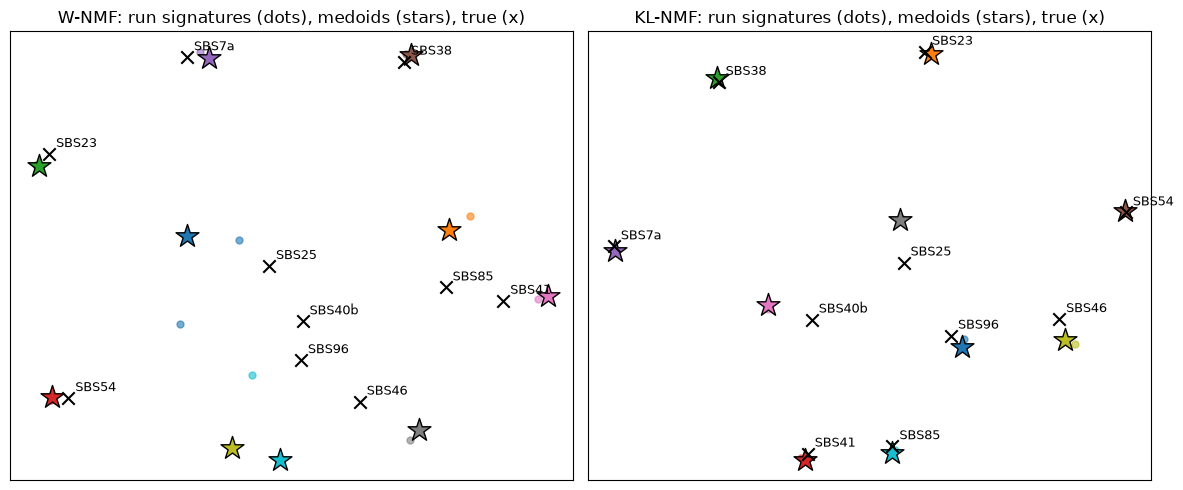

In [9]:
# ***** use MDS map to visualize the signature clusters and their medoids
from sklearn.manifold import MDS

def unit(A):
    return A / np.linalg.norm(A, axis=0, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, sig_runs) in zip(axes, [("W-NMF", runs_wnmf), ("KL-NMF", runs_klnmf)]):
    pooled = np.hstack(sig_runs)                                  
    med = results[name]["medoids"]                                
    labels = np.argmax(unit(pooled).T @ unit(med), axis=1)        
    allsig = np.hstack([pooled, med, W_true])
    D = np.clip(1 - unit(allsig).T @ unit(allsig), 0, None)      
    xy = MDS(n_components=2, dissimilarity="precomputed", random_state=0).fit_transform(D)
    n_p, n_m = pooled.shape[1], med.shape[1]
    p, m, t = xy[:n_p], xy[n_p:n_p + n_m], xy[n_p + n_m:]
    for c in range(n_m):
        ax.scatter(*p[labels == c].T, s=25, alpha=0.6, color=f"C{c}")              
        ax.scatter(*m[c], marker="*", s=300, color=f"C{c}", edgecolor="k")         
    ax.scatter(*t.T, marker="x", s=80, color="k")                                   
    for i, s in enumerate(cosmic_sigs):
        ax.annotate(s, t[i], xytext=(5, 5), textcoords="offset points", fontsize=9)
    ax.set_title(f"{name}: run signatures (dots), medoids (stars), true (x)")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [10]:
from pathlib import Path

SUB_COLORS = {"C>A": "#1EBFF0",
              "C>G": "#050708",
              "C>T": "#E62725",
              "T>A": "#CBCACB",
              "T>C": "#A1CF64",
              "T>G": "#EDC8C5"}

# standard SBS96 order: grouped by substitution, then 5' base, then 3' base
order = sorted(range(96), key=lambda r: (sbs96[r][2:5], sbs96[r][0], sbs96[r][-1]))
bar_colors = [SUB_COLORS[sbs96[r][2:5]] for r in order]

methods = list(results)
for i, sig in enumerate(cosmic_sigs):
    fig, axes = plt.subplots(1 + len(methods), 1, figsize=(10, 2.2 * (1 + len(methods))), sharex=True)
    axes[0].bar(range(96), W_true[order, i], color=bar_colors, width=0.8)
    axes[0].set_title(f"{sig}: true (COSMIC)", loc="left", fontweight="bold")
    for ax, name in zip(axes[1:], methods):
        res = results[name]
        est = res["medoids"][:, res["idx"][i]]               # medoid matched to this true signature
        ax.bar(range(96), est[order], color=bar_colors, width=0.8)
        ax.set_title(f"{name}   cos = {res['cos'][i]:.3f}", loc="left")
    ymax = max(ax.get_ylim()[1] for ax in axes)              # same y scale in all panels
    for ax in axes:
        ax.set_ylim(0, ymax)
        ax.set_ylabel("probability")
    axes[-1].set_xticks(range(0, 96, 16)); axes[-1].set_xticklabels(list(SUB_COLORS), ha="left")
    fig.tight_layout()
    fig.savefig(os.path.join(outputdir, f"{sig}.png"), dpi=150)
    plt.close(fig)                                           # free memory, nothing shown inline

print(f"saved {len(cosmic_sigs)} plots to {outputdir}")

saved 10 plots to ./tmp_output/sig_plots


In [19]:
import datetime
datetime.datetime.now()

datetime.datetime(2026, 11, 11, 14, 22, 41, 20949)

In [15]:
sampleInputdf = pd.DataFrame(X, index=sbs96)
sampleInputdf.columns = [f"Sample{i}" for i in range(1, sampleInputdf.shape[1] + 1)]
sampleInputdf.to_csv(os.path.join("sampleInput.csv"), float_format="%.10g")